# Шаг 3. Модель риска отмены брони

**Проект:** отмены бронирований в отелях — прогноз и политика предоплаты.

**Цель шага:** построить модель, которая в момент бронирования оценивает вероятность отмены, честно сравнить её с простыми правилами и выбрать порог «брать предоплату» по деньгам.

**Содержание:** 1. Постановка · 2. Сплит по времени · 3. Признаки и утечки · 4. Ловушка утечки · 5. Бенчмарки · 6. Модели и выбор CatBoost · 7. Калибровка · 8. Интерпретация · 9. Порог по деньгам · 10. Итог на тесте · 11. Выводы

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import Image

from src.baselines import lead_segment_rates, lead_segment_score, lead_time_score
from src.data import load_raw
from src.evaluation import (
    METRICS_PATH, best_threshold, calibration_table, loss_curve, loss_sensitivity, losses, score_table,
    threshold_report, threshold_sensitivity, value_at_risk,
)
from src.model_features import EXCLUDED, model_frame
from src.models import (
    as_category, fit_calibrator, fit_catboost, fit_hist_gb, fit_logistic, odds_ratios, save_catboost,
    tune_catboost,
)
from src.pipeline import build_dataset
from src.plots import FIGURES_DIR, save_figure, set_style
from src.split import random_split, split_summary, time_split

%config InlineBackend.figure_format = 'svg'
set_style()
pd.set_option('display.max_colwidth', None)
df, _ = build_dataset(load_raw())
train, valid, test = time_split(df)
(X_train, y_train), (X_valid, y_valid), (X_test, y_test) = map(model_frame, (train, valid, test))

Собираем очищенный датасет шага 1 (вариант C, одна строка — одна бронь-решение) и сразу делим его по времени; что это за части — в разделе 2. Графики выводятся в SVG — чёткие на любом экране.

## 1. Постановка

**Что делаем.** Фиксируем, что именно предсказываем и чем меряем качество.

- **Что предсказываем:** вероятность того, что бронь будет отменена (`is_canceled`), по данным, известным **в момент бронирования**.
- **Для чего:** revenue-менеджер решает, с какой брони брать предоплату. Модель ранжирует брони по риску, порог по деньгам (раздел 9) превращает риск в решение «да/нет».
- **Чем меряем:** **PR-AUC** — главная метрика: она показывает, насколько хорошо модель находит отмены среди всех броней, и честно учитывает, что отмен меньше, чем заездов (случайная модель даёт PR-AUC, равный доле отмен). **ROC-AUC** — вероятность того, что случайная отменённая бронь получит риск выше, чем случайная неотменённая (0,5 — угадывание, 1 — идеал). **Калибровка** — совпадает ли «вероятность 30 %» с реальной долей отмен 30 %: это важно, потому что по вероятностям считаем деньги.

**Вывод.** Задача — бинарная классификация с прицелом на деньги: модель должна хорошо ранжировать брони (PR-AUC, ROC-AUC) и давать честные вероятности (калибровка).

## 2. Сплит по времени

**Что делаем.** Делим брони по дате заезда: ранние 60 % — обучение, следующие 20 % — валидация (на ней выбираем модель, настройки, калибровку и порог), последние 20 % — тест, который открываем один раз в конце. Так мы имитируем реальную работу: модель учится на прошлом и предсказывает будущее.

In [2]:
split_summary({'обучение': train, 'валидация': valid, 'тест': test})

,bookings,first_arrival,last_arrival,cancel_rate
обучение,51926,2015-07-01,2016-11-29,0.247
валидация,17340,2016-11-30,2017-05-02,0.293
тест,17351,2017-05-03,2017-08-31,0.348


Таблица показывает три части: `bookings` — число броней, `first_arrival` и `last_arrival` — первая и последняя дата заезда, `cancel_rate` — доля отмен. Обучение — 51 926 броней с заездом с 01.07.2015 по 29.11.2016, валидация — 17 340 (30.11.2016–02.05.2017), тест — 17 351 (03.05.2017–31.08.2017); вместе 86 617, примерно 60/20/20 %. Части не пересекаются по датам, поэтому модель нигде не «подсматривает» будущее. Доля отмен растёт от части к части: 24,7 % → 29,3 % → 34,8 %.

### Почему 60/20/20, а не 70/15/15 или 75/15/10

**Что делаем.** Доли частей выбраны заранее, до любых результатов. Показываем, какие периоды достаются обучению, валидации и тесту при трёх вариантах долей. Доли отмен по частям выбранного сплита 60/20/20 уже показаны выше — это описание данных, по ним доли не выбирались. Для вариантов 70/15/15 и 75/15/10 таблица сознательно содержит только размеры и даты, без доли отмен и метрик: сравнивать варианты по исходу теста нельзя.

In [3]:
split_options = {'60/20/20': (0.6, 0.2), '70/15/15': (0.7, 0.15), '75/15/10': (0.75, 0.15)}
pd.concat({
    name: split_summary(dict(zip(('обучение', 'валидация', 'тест'), time_split(df, *shares))))
    .drop(columns='cancel_rate')
    for name, shares in split_options.items()
})

bookings first_arrival last_arrival
60/20/20 обучение     51926    2015-07-01   2016-11-29
         валидация    17340    2016-11-30   2017-05-02
         тест         17351    2017-05-03   2017-08-31
70/15/15 обучение     60618    2015-07-01   2017-02-24
         валидация    12876    2017-02-25   2017-05-31
         тест         13123    2017-06-01   2017-08-31
75/15/10 обучение     64922    2015-07-01   2017-04-01
         валидация    12964    2017-04-02   2017-07-01
         тест          8731    2017-07-02   2017-08-31

Таблица показывает для трёх вариантов долей число броней (`bookings`) и первую и последнюю дату заезда в каждой части. Раз делим по времени, доля — это не только размер, но и период:

- **60/20/20:** обучение — 01.07.2015–29.11.2016 (почти 17 месяцев, каждый месяц года встречается хотя бы раз), валидация — 30.11.2016–02.05.2017 (зима и весна, около 5 месяцев), тест — 03.05.2017–31.08.2017 (весна и лето, 4 месяца).
- **70/15/15:** валидация — 25.02.2017–31.05.2017 (около 3 месяцев, 12 876 броней), тест — 01.06.2017–31.08.2017 (только лето, 3 месяца, 13 123 брони).
- **75/15/10:** валидация — 02.04.2017–01.07.2017 (около 3 месяцев, 12 964 брони), тест — 02.07.2017–31.08.2017 (только июль и август — пик сезона, 8 731 бронь).

Аргументы за 60/20/20:

1. **Данных много.** Даже 20 % — это 17 351 бронь в тесте, из них около 6 тыс. отмен (17 351 × 34,8 % из таблицы выше), и 17 340 броней в валидации. Большие доли обучения нужны, когда данных мало и каждая бронь на счету; здесь обучению и при 60 % достаётся 51 926 броней.
2. **Тест шире.** При 60/20/20 тест охватывает четыре месяца, с мая по август. При 75/15/10 он сужается до июля–августа: проверка покажет, как модель работает в пик сезона, но не в остальное время, и опирается на 8 731 бронь вместо 17 351.
3. **Валидация длиннее.** На валидации выбираем модель и её настройки, обучаем калибровку и подбираем порог по деньгам (разделы 6, 7 и 9). При 60/20/20 это около 5 месяцев и 17 340 броней, при 70/15/15 и 75/15/10 — около 3 месяцев и примерно 13 тыс. броней. Чем короче период, тем сильнее эти решения подстраиваются под его особенности.
4. **Плюс больших долей обучения — честно.** У модели больше данных (60 618 или 64 922 брони вместо 51 926), и они свежее: при 75/15/10 обучение доходит до 01.04.2017, а не до 29.11.2016, то есть ближе к тесту. Раз доля отмен растёт во времени (таблица выше), свежие данные могли бы уменьшить разрыв между обучением и тестом. Это реальный плюс, но он покупается более узкой и короткой проверкой.
5. **Доли выбраны до результатов.** Подбирать настройки по валидации — нормально, для этого она и нужна. Выбирать доли (или что-либо ещё) по результату на тесте нельзя: тогда тест перестанет быть независимой проверкой, и его цифры станут оптимистичными. Поэтому в таблице вариантов нет ни доли отмен, ни метрик — сравниваются только периоды.

Почему делим по времени, а не случайно, — сравнение в конце раздела 10.

**Вывод.** Сплит по времени честнее случайного: модель учится на прошлом, а проверяется на будущем, как в реальной работе. Доли 60/20/20 зафиксированы до результатов; таблица вариантов показывает, что они дают: валидации и тесту — примерно по 17 тыс. броней, тесту — четыре месяца (май–август), а не только пик сезона, как при 75/15/10. Но доля отмен растёт: модель учится на периоде, где отменяли 24,7 % броней, а работать ей придётся там, где отменяют 29,3 % (валидация) и 34,8 % (тест). Значит, её вероятности могут оказаться заниженными — поэтому ниже нужны калибровка (раздел 7) и отдельная проверка на тесте (раздел 10).

## 3. Признаки и утечки

**Что делаем.** Решаем, какие колонки модель может видеть. Правило одно: только то, что известно в момент бронирования. Четыре явные утечки нашли ещё на шаге 1 (схема 07); здесь показываем, как нашли ещё две подозрительные колонки — парковку и страну — и сколько «стоит» честность.

In [4]:
pd.Series(EXCLUDED, name='причина исключения')

reservation_status                            утечка: известно только после заезда или отмены
reservation_status_date                       утечка: известно только после заезда или отмены
assigned_room_type                            утечка: известно только после заезда или отмены
booking_changes                               утечка: известно только после заезда или отмены
required_car_parking_spaces    подозрение на утечку: у броней с парковкой нет ни одной отмены
country                                подозрение на утечку: страну часто уточняют при заезде
Name: причина исключения, dtype: str

**Утечка** — колонка, которая в момент бронирования ещё неизвестна и «подсказывает» модели ответ; с ней модель блестяще работает на исторических данных и бесполезна в реальности. Список исключённых колонок: четыре явные утечки шага 1 (`reservation_status` и его дата — это сам исход, `assigned_room_type` назначают при заезде, `booking_changes` накапливаются, пока бронь живёт) и две подозрительные — парковка и страна. Число спецзапросов (`total_of_special_requests`) — тоже счётчик, но его оставляем: это пожелания к номеру (например, кровать или этаж), которые естественно указать при бронировании, а в описании датасета, в отличие от `booking_changes`, нет оговорки, что он копится до заезда или отмены. Даты запроса в данных нет, поэтому часть запросов могла добавиться позже — у отменённой брони на это меньше времени, и тогда сила признака завышена; это ограничение (раздел 11). Ниже по шагам показываем, почему подозрение пало на парковку и страну.

In [5]:
pd.crosstab(df['required_car_parking_spaces'] > 0, df['is_canceled'], margins=True)

is_canceled,0,1,All
required_car_parking_spaces,,,
False,55360,23968,79328
True,7289,0,7289
All,62649,23968,86617


Шаг (а) — парковка. Таблица делит брони на «без парковки» (`False`) и «с парковкой» (`True`) и считает, сколько из них заехали (0) и отменены (1). Среди 79 328 броней без парковки отменено 23 968 (около 30 %), а среди 7 289 броней с парковкой — ни одной. При обычной доле отмен среди них ожидалось бы около 2 200 отмен; ровно ноль так не бывает, если парковку указывают при бронировании. Правдоподобное объяснение — парковку записывают при заезде, то есть только у тех, кто приехал: тогда колонка фактически говорит «гость приехал». Оговорка: проверку утечек делаем по всем данным, включая тестовый период, — это описательная проверка колонок; модели и их метрики теста не касаются до раздела 10.

In [6]:
country_share = pd.crosstab(df['country'].eq('PRT'), df['is_canceled'], normalize='columns').round(3)
country_share

is_canceled,0,1
country,,
False,0.727,0.593
True,0.273,0.407


Шаг (б) — страна. Таблица показывает долю гостей из Португалии (`PRT`, строка `True`) отдельно среди заехавших (0) и отменённых (1) броней. Среди заехавших португальцев 27,3 %, а среди отменённых — 40,7 %, в полтора раза больше. Возможны два объяснения. Гипотеза утечки: при бронировании страну часто ставят «по умолчанию» (Португалия — страна отелей), а у тех, кто приехал, уточняют по документам на стойке; тогда у отменённых броней страна остаётся «португальской», и колонка частично несёт информацию об исходе. Конкурирующее объяснение: португальские (внутренние) гости действительно чаще отменяют — например, им проще перенести поездку. Данные не позволяют отличить одно от другого: в них нет даты, когда страну записали.

In [7]:
ablation = {}
for name, extra in {'без парковки и страны (основная)': (), '+ парковка': ('required_car_parking_spaces',),
                    '+ страна': ('country',),
                    '+ парковка и страна': ('required_car_parking_spaces', 'country')}.items():
    X_tr, _ = model_frame(train, extra)
    X_va, _ = model_frame(valid, extra)
    ablation[name] = fit_catboost((X_tr, y_train), (X_va, y_valid)).predict_proba(X_va)[:, 1]
score_table(y_valid, ablation).round(3)

,pr_auc,roc_auc
без парковки и страны (основная),0.634,0.796
+ парковка,0.648,0.816
+ страна,0.658,0.819
+ парковка и страна,0.674,0.836


Шаг (в) — сколько «стоит» честность. Обучаем одну и ту же модель CatBoost четыре раза: без двух подозрительных колонок и с ними, и сравниваем на валидации. Парковка добавляет к PR-AUC 0,014 (0,634 → 0,648), страна — 0,024 (→ 0,658), обе вместе — 0,040 (→ 0,674); ROC-AUC растёт с 0,796 до 0,836. Прирост заметный, но, если наши подозрения верны, он получен за счёт подсказки об исходе, а не за счёт настоящего знания о брони.

**Вывод.** Шаг (г) — решение: исключаем и парковку, и страну. Обе колонки, возможно, заполняют или уточняют после заезда: у 7 289 броней с парковкой ноль отмен, а доля Португалии среди отменённых (40,7 %) заметно выше, чем среди заехавших (27,3 %). Доказать утечку по этим данным нельзя — для страны, например, возможна и реальная связь, — поэтому исключение — осторожное решение: лучше недооценить модель, чем дать ей подсказку, которой при бронировании не будет. Цена осторожности известна: PR-AUC 0,634 вместо 0,674 (−0,040). Честная модель скромнее, зато не обманывает.

## 4. Ловушка утечки

**Что делаем.** Показываем, что будет, если дать модели колонку из будущего — `reservation_status` (итог брони: заезд, отмена или неприезд).

In [8]:
X_leak_tr, _ = model_frame(train, ('reservation_status',))
X_leak_va, _ = model_frame(valid, ('reservation_status',))
leak_model = fit_catboost((X_leak_tr, y_train), (X_leak_va, y_valid))
score_table(y_valid, {'CatBoost + reservation_status': leak_model.predict_proba(X_leak_va)[:, 1]}).round(3)

,pr_auc,roc_auc
CatBoost + reservation_status,1.0,1.0


Добавляем к признакам `reservation_status` (итог брони) и обучаем CatBoost так же, как основную модель. На валидации PR-AUC и ROC-AUC равны 1,0 — модель не ошибается ни разу. Это не успех, а ошибка: колонка и есть ответ («Canceled» и «No-Show» — отмена, «Check-Out» — заезд), модели достаточно её прочитать. На схеме 07 шага 2 статус появляется в самом конце жизни брони — в момент бронирования его нет.

**Вывод.** Идеальная метрика на реальных данных — тревожный сигнал, а не повод для радости. Именно поэтому все колонки, которые на схеме 07 появляются после создания брони, исключены, а парковка и страна проверены отдельно (раздел 3). Все дальнейшие цифры получены только на признаках, известных в момент бронирования.

## 5. Бенчмарки

**Что делаем.** Прежде чем строить модели, меряем два простых правила, которые менеджер мог бы применить без машинного обучения: «чем раньше бронь, тем выше риск» и «доля отмен в ячейке срок брони × сегмент» (по обучению). Модель имеет смысл, только если заметно лучше них.

In [9]:
rates = lead_segment_rates(train)
valid_scores = {
    'правило: срок брони': lead_time_score(valid),
    'правило: срок + сегмент': lead_segment_score(rates, valid, fallback=y_train.mean()),
}
score_table(y_valid, valid_scores).round(3)

,pr_auc,roc_auc
правило: срок брони,0.449,0.684
правило: срок + сегмент,0.487,0.738


Правило «срок брони» ставит бронь тем выше в списке риска, чем раньше её сделали; правило «срок + сегмент» берёт долю отмен на обучении в ячейке «группа срока × сегмент продаж». На валидации первое даёт PR-AUC 0,449 и ROC-AUC 0,684, второе — 0,487 и 0,738. Для сравнения: случайное угадывание даёт PR-AUC, равный доле отмен на валидации, — 0,293. Простые правила уже заметно лучше случайности: срок и сегмент действительно связаны с отменами (это H1 и H2 шага 2).

**Вывод.** Планка для моделей — PR-AUC 0,487 и ROC-AUC 0,738 правила «срок + сегмент». Это то, что менеджер получил бы из простой таблицы без машинного обучения; модель имеет смысл, только если заметно превосходит эту планку.

## 6. Модели и выбор CatBoost

**Что делаем.** Обучаем три модели на одних и тех же признаках: логистическую регрессию (понятная, с логарифмом у срока брони и цены — у них длинные хвосты), HistGradientBoosting из scikit-learn и CatBoost. Затем подбираем настройки CatBoost и разбираем развилку: почему основная модель — CatBoost.

In [10]:
logistic = fit_logistic(X_train, y_train)
hist_gb = fit_hist_gb(X_train, y_train)
catboost_default = fit_catboost((X_train, y_train), (X_valid, y_valid))
valid_scores |= {
    'логистическая регрессия': logistic.predict_proba(X_valid)[:, 1],
    'HistGradientBoosting': hist_gb.predict_proba(as_category(X_valid))[:, 1],
    'CatBoost (базовые настройки)': catboost_default.predict_proba(X_valid)[:, 1],
}
score_table(y_valid, valid_scores).round(3)

,pr_auc,roc_auc
правило: срок брони,0.449,0.684
правило: срок + сегмент,0.487,0.738
логистическая регрессия,0.632,0.783
HistGradientBoosting,0.621,0.792
CatBoost (базовые настройки),0.634,0.796


Таблица дополнила правила тремя моделями (все — на одних и тех же признаках и одной валидации). Логистическая регрессия получила PR-AUC 0,632 и ROC-AUC 0,783, HistGradientBoosting — 0,621 и 0,792, CatBoost с базовыми настройками (глубина 6, скорость 0,1) — 0,634 и 0,796. Все три модели опережают лучшее правило (0,487) примерно на 0,13–0,15 PR-AUC, а между собой различаются лишь на 0,01–0,02. CatBoost обучается с **ранней остановкой**: деревья добавляются, пока качество на валидации растёт, и обучение прекращается, когда оно перестаёт улучшаться — так модель не «заучивает» обучающие данные.

In [11]:
catboost, grid = tune_catboost((X_train, y_train), (X_valid, y_valid))
valid_scores['CatBoost (настроенный)'] = catboost.predict_proba(X_valid)[:, 1]
grid.round(4)

,depth,learning_rate,trees,pr_auc
0,4,0.05,726,0.6386
1,4,0.10,335,0.6396
2,6,0.05,460,0.6352
3,6,0.10,318,0.6341
4,8,0.05,227,0.6284
5,8,0.10,37,0.6284


Перебираем шесть сочетаний двух настроек CatBoost: глубину деревьев (4, 6, 8) и скорость обучения (0,05 и 0,1); `trees` — сколько деревьев оставила ранняя остановка, `pr_auc` — качество на валидации. Лучшее сочетание — глубина 4 и скорость 0,1 (335 деревьев, PR-AUC 0,6396); худшие — глубина 8 (0,6284). Весь разброс — около 0,01: настройки почти не влияют на качество, неглубокие деревья немного лучше. Эта модель дальше называется «CatBoost (настроенный)».

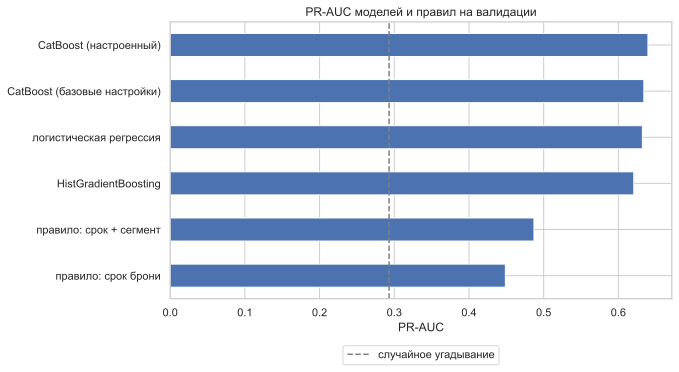

In [12]:
comparison = score_table(y_valid, valid_scores)
fig, ax = plt.subplots()
comparison['pr_auc'].sort_values().plot.barh(ax=ax)
chance = ax.axvline(y_valid.mean(), color='grey', linestyle='--', label='случайное угадывание')
ax.set_title('PR-AUC моделей и правил на валидации')
ax.set_xlabel('PR-AUC')
ax.legend(handles=[chance], loc='upper center', bbox_to_anchor=(0.5, -0.15))
save_figure(fig, '08_model_comparison')
plt.show()

График сравнивает PR-AUC всех моделей и правил на валидации; пунктир — уровень случайного угадывания (0,293). Верхние четыре столбца (настроенный CatBoost — 0,640, CatBoost с базовыми настройками — 0,634, логистическая регрессия — 0,632, HistGradientBoosting — 0,621) почти одинаковой длины, правила заметно короче (0,487 и 0,449). Главный разрыв — между правилами и моделями, а не между самими моделями.

### Развилка: почему CatBoost

**Варианты.** Две модели на деревьях решений (бустинг — много небольших деревьев, каждое исправляет ошибки предыдущих): HistGradientBoosting из scikit-learn и CatBoost. Логистическая регрессия — простой ориентир.

**Критерии.**

1. *Работа с категориями без one-hot.* В данных много текстовых признаков (сегмент, тип клиента, депозит, тип номера). CatBoost принимает их как есть и сам кодирует по доле отмен; HistGradientBoosting тоже умеет категории, но требует перевести их в специальный тип; логистической регрессии нужен one-hot — каждая категория превращается в отдельную колонку 0/1.
2. *Качество на одной и той же валидации.* CatBoost с базовыми настройками — PR-AUC 0,634 и ROC-AUC 0,796, HistGradientBoosting — 0,621 и 0,792; после настройки CatBoost — 0,640 и 0,798. Разница в пользу CatBoost — около 0,01–0,02 PR-AUC. Сравнение не вполне равное: CatBoost подбирали по сетке настроек и с ранней остановкой по валидации, а HistGradientBoosting обучен с библиотечными настройками по умолчанию (в них тоже есть ранняя остановка, но по 10 % обучающих данных, а не по валидации), поэтому часть разницы может объясняться настройкой, а не самой моделью.
3. *Объяснимость.* Для CatBoost есть быстрый и точный расчёт SHAP (раздел 8): можно показать, почему конкретная бронь получила высокий риск.
4. *Распространённость на практике.* CatBoost и похожие бустинги — стандартный выбор для табличных данных в индустрии.

**Вывод развилки.** Разница в качестве мала, поэтому CatBoost выбран не за сотые доли PR-AUC, а за удобство работы с категориями и объяснимость. Честно: логистическая регрессия почти не уступает (PR-AUC 0,632 против 0,640) — значит, данные хорошо описываются простыми связями вида «чем больше X, тем выше риск», и сложная модель добавляет немного. Важная оговорка: ранняя остановка и выбор настроек сделаны по валидации, поэтому её цифры для CatBoost слегка оптимистичны — честная оценка будет на тесте (раздел 10).

**Вывод.** Все модели заметно лучше простых правил: PR-AUC 0,62–0,64 против 0,487 у лучшего правила и 0,293 у случайного угадывания. Основная модель — настроенный CatBoost (глубина 4, скорость 0,1, 335 деревьев, PR-AUC 0,640 на валидации), но его преимущество над логистической регрессией (0,632) и HistGradientBoosting (0,621) мало; выбор сделан ради удобства и объяснимости.

## 7. Калибровка

**Что делаем.** Проверяем, можно ли верить вероятностям CatBoost как процентам: если модель говорит «30 %», отменяют ли примерно 30 % таких броней? Если нет — калибруем (изотоническая регрессия на валидации).

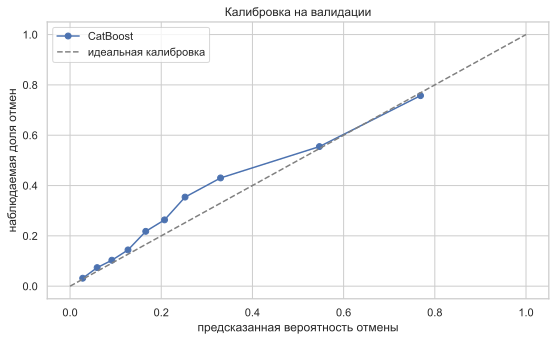

,predicted,observed
0,0.028,0.032
1,0.059,0.074
2,0.092,0.103
3,0.127,0.144
4,0.166,0.218
5,0.207,0.264
6,0.252,0.354
7,0.330,0.430
8,0.547,0.555
9,0.769,0.757


In [13]:
calibration_raw = calibration_table(y_valid, valid_scores['CatBoost (настроенный)'])
fig, ax = plt.subplots()
ax.plot(calibration_raw['predicted'], calibration_raw['observed'], marker='o', label='CatBoost')
ax.plot([0, 1], [0, 1], color='grey', linestyle='--', label='идеальная калибровка')
ax.set_title('Калибровка на валидации')
ax.set_xlabel('предсказанная вероятность отмены')
ax.set_ylabel('наблюдаемая доля отмен')
ax.legend()
save_figure(fig, '09_calibration')
plt.show()
calibration_raw.round(3)

Брони делятся на 10 равных групп по прогнозу; в каждой сравниваем средний прогноз (`predicted`) с реальной долей отмен (`observed`). Если точки лежат на пунктирной диагонали, вероятностям можно верить как процентам. Почти везде точки выше диагонали — модель занижает риск: при прогнозе 0,252 отменяют 35,4 %, при 0,330 — 43,0 %, при 0,166 — 21,8 %. У самых рискованных броней прогноз и факт близки (0,547 против 0,555 и 0,769 против 0,757).

In [14]:
calibrator = fit_calibrator(valid_scores['CatBoost (настроенный)'], y_valid)
valid_proba = calibrator.predict(valid_scores['CatBoost (настроенный)'])
pd.DataFrame({'средний прогноз до калибровки': [valid_scores['CatBoost (настроенный)'].mean()],
              'средний прогноз после': [valid_proba.mean()],
              'доля отмен на валидации': [y_valid.mean()]}).round(3)

,средний прогноз до калибровки,средний прогноз после,доля отмен на валидации
0,0.258,0.293,0.293


Изотоническая регрессия — простая поправка, которая «сдвигает» прогнозы модели так, чтобы они совпали с наблюдаемой долей отмен, не меняя порядка броней (качество ранжирования, PR-AUC и ROC-AUC, почти не меняется: близкие прогнозы могут слиться в одну ступеньку). До калибровки средний прогноз на валидации — 0,258, после — 0,293, ровно как доля отмен на валидации (0,293). Калибратор обучен на той же валидации, поэтому здесь совпадение ожидаемо; проверка на новых данных — на тесте (раздел 10).

**Вывод.** CatBoost занижает вероятности отмены: средний прогноз 0,258 при реальной доле 0,293. Вероятно, это следствие сдвига во времени — модель обучена на периоде, где отменяли 24,7 % броней. Калибровка исправляет это, и дальше мы работаем с калиброванными вероятностями — они нужны, чтобы считать деньги в разделе 9.

## 8. Интерпретация

**Что делаем.** Разбираем, на что опирается модель: SHAP показывает вклад каждого признака в риск конкретной брони; отношения шансов логистической регрессии — то же для простой модели. Сверяем с гипотезами H1–H4 шага 2. Важно: это описание модели, а не причины отмен.

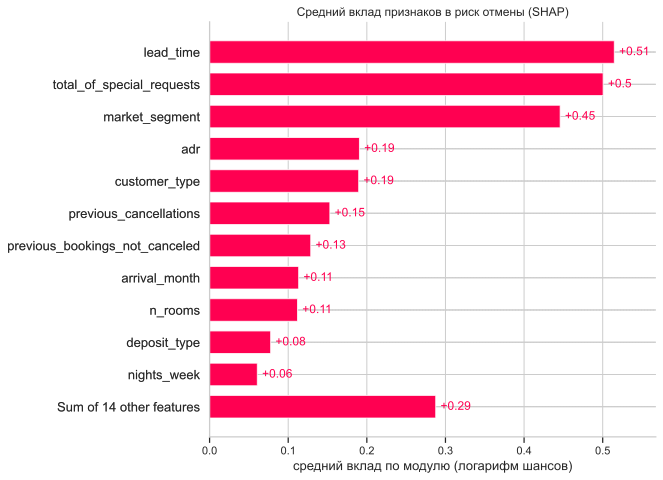

In [15]:
shap_values = shap.TreeExplainer(catboost)(X_valid)
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title('Средний вклад признаков в риск отмены (SHAP)')
plt.xlabel('средний вклад по модулю (логарифм шансов)')
save_figure(plt.gcf(), '10_shap')
plt.show()

**SHAP** раскладывает прогноз для каждой брони на вклады признаков: сколько каждый признак добавил к риску или отнял от него (в единицах модели — логарифме шансов, поэтому важно сравнение, а не сами числа). График показывает средний по броням размер вклада без учёта знака. Нижний столбец «Sum of 14 other features» — суммарный вклад прочих 14 признаков (0,29): по отдельности каждый из них слабее показанных. Больше всего модель опирается на срок брони (`lead_time`, 0,51), число спецзапросов (0,50) и сегмент продаж (0,45); дальше — цена за ночь (`adr`) и тип клиента (по 0,19), прошлые отмены (0,15) и прошлые неотменённые брони (0,13). Тип депозита в среднем даёт только 0,08: брони «без возврата» редки (1 037 из 86 617, шаг 2, раздел 2), поэтому у большинства броней этот признак почти ничего не меняет.

In [16]:
examples = {'самая рискованная': int(np.argmax(valid_proba)), 'самая надёжная': int(np.argmin(valid_proba))}
pd.concat({
    name: pd.DataFrame({'значение': X_valid.iloc[i], 'вклад SHAP': shap_values.values[i]})
    .sort_values('вклад SHAP', key=abs, ascending=False).head(6)
    for name, i in examples.items()
}).round(2)

значение  вклад SHAP
самая рискованная deposit_type                    Non Refund        3.29
                  n_rooms                                 23        1.48
                  total_of_special_requests                0        0.70
                  lead_time                              183        0.62
                  customer_type                    Transient        0.44
                  market_segment                      Groups       -0.37
самая надёжная    lead_time                                0       -1.74
                  previous_bookings_not_canceled           1       -1.20
                  arrival_month                           12       -0.43
                  adr                                   43.0       -0.31
                  total_of_special_requests                0        0.30
                  customer_type                    Transient        0.12

Таблица раскладывает прогноз для двух броней валидации: одной из самых рискованных и одной из самых надёжных (после калибровки таких броней с одинаковым прогнозом может быть несколько, берём первую). У рискованной главный вклад даёт депозит «без возврата» (+3,29) — во много раз больше среднего вклада любого признака на графике; дальше — 23 номера в брони (+1,48), ноль спецзапросов (+0,70) и бронь за 183 дня (+0,62). У надёжной риск снижают бронь в день заезда (срок 0, −1,74) и одна прошлая неотменённая бронь гостя (−1,20). Сильный вклад депозита «без возврата» — та самая аномалия шага 2: это крупные брони (в среднем около 14 номеров, предположительно групповые), и 94,7 % из них отменены (шаг 2, раздел 2).

In [17]:
odds_ratios(logistic).head(12).round(2)

cat__deposit_type_Non Refund           7.35
cat__deposit_type_Refundable           0.28
cat__market_segment_Offline TA/TO      0.33
cat__deposit_type_No Deposit           0.35
num__previous_cancellations            2.29
num__previous_bookings_not_canceled    0.45
num__total_of_special_requests         0.52
log__lead_time                         1.90
cat__market_segment_Groups             0.53
cat__market_segment_Aviation           1.83
cat__market_segment_Online TA          1.61
cat__customer_type_Transient-Party     0.69
dtype: float64

**Отношение шансов** логистической регрессии показывает, во сколько раз меняются шансы отмены (отношение «отменят» к «не отменят») при прочих равных: больше 1 — риск выше, меньше 1 — ниже. Для числовых признаков — при росте на одно стандартное отклонение; у срока брони и цены сначала берётся логарифм (длинные хвосты), поэтому 1,90 у `log__lead_time` — это рост на одно стандартное отклонение логарифма срока. У категорий в этой модели нет «базового» уровня: каждый уровень сравнивается с условным средним уровнем признака, поэтому число у отдельной категории само по себе мало что значит — сравнивать имеет смысл уровни одного признака между собой, деля одно отношение шансов на другое. Так, депозит «без возврата» против «без депозита» — 7,35 / 0,35 ≈ 21: шансы отмены примерно в 21 раз выше; онлайн-агентства против офлайн-агентств — 1,61 / 0,33 ≈ 4,9 раза. Среди числовых признаков шансы сильнее всего повышают прошлые отмены гостя (2,29) и срок брони (1,90), снижают — прошлые неотменённые брони гостя (0,45) и спецзапросы (0,52).

**Вывод.** Обе модели согласны с гипотезами шага 2. H1 (срок): срок брони — первый по силе признак CatBoost (SHAP 0,51), почти вровень со спецзапросами (0,50), отношение шансов 1,90 на одно стандартное отклонение логарифма срока. H2 (сегмент): сегмент — третий по силе (0,45), у онлайн-агентств шансы отмены примерно в 4,9 раза выше, чем у офлайн-агентств (1,61 / 0,33). H3 (спецзапросы): второй по силе признак, отношение шансов 0,52. H4 (повторные гости): видна через историю гостя — прошлые неотменённые брони снижают шансы (0,45), прошлые отмены повышают (2,29). Самый сильный признак для отдельной брони — депозит «без возврата» (+3,29 по SHAP у рискованной брони; в логистической регрессии шансы примерно в 21 раз выше, чем «без депозита»). Это описание того, на что опирается модель, — **связь, а не причина**: из этих чисел не следует, что изменение признака (например, срока брони) само изменит вероятность отмены.

## 9. Порог по деньгам

**Что делаем.** Превращаем вероятность в решение «брать предоплату или нет». Предоплату берём, если вероятность отмены ≥ порога. Ошибиться можно двумя способами: **пропустить отмену** (номер пустует — теряем стоимость брони × доля, которую не удаётся перепродать; допущение 50 %) и **зря напугать** надёжного гостя (теряем стоимость × вероятность, что он уйдёт; допущение 10 %). Брони «без возврата» уже оплачены — их отмена ничего не стоит. Выбираем порог с минимальными потерями на валидации и проверяем, как он зависит от допущений.

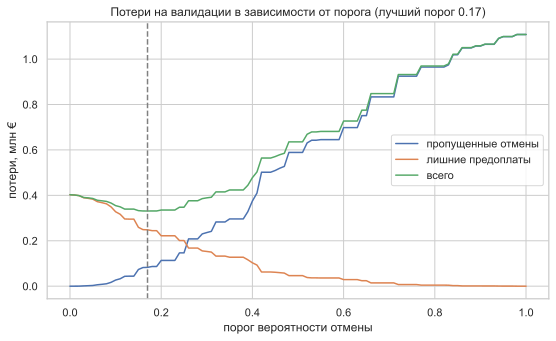

0.17

In [18]:
valid_value = value_at_risk(valid)
curve = loss_curve(y_valid, valid_proba, valid_value)
threshold = best_threshold(curve)
fig, ax = plt.subplots()
(curve / 1e6).plot(ax=ax)
ax.axvline(threshold, color='grey', linestyle='--')
ax.set_title(f'Потери на валидации в зависимости от порога (лучший порог {threshold:.2f})')
ax.set_xlabel('порог вероятности отмены')
ax.set_ylabel('потери, млн €')
ax.legend(['пропущенные отмены', 'лишние предоплаты', 'всего'])
save_figure(fig, '11_loss_curve')
plt.show()
threshold

Для каждого порога от 0 до 1 считаем потери на валидации: синяя линия — пропущенные отмены (стоимость отменённых броней без предоплаты × 50 %), оранжевая — лишние предоплаты (стоимость надёжных броней с предоплатой × 10 %), зелёная — сумма. Чем выше порог, тем меньше лишних предоплат и больше пропущенных отмен. Минимум суммы — при пороге 0,17 (пунктир). Он близок к теоретическому: предоплата выгодна, когда ожидаемая потеря от отмены больше ожидаемой потери гостя, то есть при вероятности выше 0,1 / (0,5 + 0,1) = 0,1 / 0,6 ≈ 0,17. Совпадение ожидаемо: калибратор обучен на той же валидации, поэтому вероятности на ней почти точные, а при точных вероятностях порог задаётся соотношением двух цен ошибок.

In [19]:
pd.DataFrame({
    'без предоплаты': losses(y_valid, valid_proba, valid_value, np.inf),
    f'порог {threshold:.2f}': losses(y_valid, valid_proba, valid_value, threshold),
    'предоплата со всех': losses(y_valid, valid_proba, valid_value, 0.0),
}).T.div(1e6).round(2)

,missed,false_alarm,total
без предоплаты,1.13,0.00,1.13
порог 0.17,0.08,0.25,0.33
предоплата со всех,0.00,0.40,0.40


Сравниваем три политики на валидации (в млн €): `missed` — потери от пропущенных отмен, `false_alarm` — от лишних предоплат, `total` — сумма. Без предоплаты отель теряет 1,13 млн €, с предоплатой у всех — 0,40, при пороге 0,17 — 0,33 (0,08 на пропущенных отменах и 0,25 на лишних предоплатах). Модель снижает потери примерно на 71 % относительно «без предоплаты» и на 0,07 млн € относительно «предоплата со всех».

In [20]:
pd.Series(threshold_report(y_valid, valid_proba, threshold)).round(3)

precision       0.430
recall          0.879
prepay_share    0.599
dtype: float64

Показатели решения при пороге 0,17: `prepay_share` — доля броней, с которых просим предоплату, `recall` — доля отмен, которые попали под предоплату, `precision` — доля действительно отменённых среди броней с предоплатой. Предоплату просим у 59,9 % броней, ловим 87,9 % отмен, но только 43,0 % из «подозрительных» броней действительно отменяются. Порог низкий из-за соотношения цен ошибок: пропущенная отмена стоит 50 % стоимости брони, а лишняя предоплата в среднем — 10 % (гость уходит с вероятностью 10 %). Ожидаемая цена первой ошибки в пять раз выше второй, поэтому выгоднее перестраховаться.

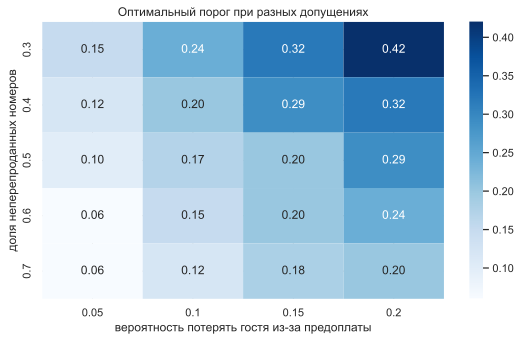

In [21]:
sensitivity = threshold_sensitivity(y_valid, valid_proba, valid_value, [0.3, 0.4, 0.5, 0.6, 0.7],
                                    [0.05, 0.1, 0.15, 0.2])
fig, ax = plt.subplots()
sns.heatmap(sensitivity, annot=True, fmt='.2f', cmap='Blues', ax=ax)
ax.set_title('Оптимальный порог при разных допущениях')
ax.set_xlabel('вероятность потерять гостя из-за предоплаты')
ax.set_ylabel('доля неперепроданных номеров')
save_figure(fig, '12_threshold_sensitivity')
plt.show()

Тепловая карта показывает оптимальный порог при других допущениях: строки — доля стоимости, которую не удаётся вернуть перепродажей номера, столбцы — вероятность потерять гостя из-за предоплаты. Порог меняется от 0,06 (перепродать трудно — 0,6–0,7, гости почти не уходят — 0,05) до 0,42 (перепродать легко — 0,3, уходит каждый пятый — 0,2). Значения близки к теоретическим `loss_prob / (unsold_share + loss_prob)`: например, для 0,3 и 0,2 это 0,4 (на карте 0,42). Итог: порог полностью определяется допущениями о деньгах.

In [22]:
loss_sensitivity(y_valid, valid_proba, valid_value, [0.3, 0.4, 0.5, 0.6, 0.7], [0.05, 0.1, 0.15, 0.2]).div(1e6).round(2)

,0.05,0.10,0.15,0.20
0.3,0.17,0.29,0.37,0.43
0.4,0.18,0.31,0.42,0.49
0.5,0.19,0.33,0.45,0.54
0.6,0.19,0.35,0.47,0.58
0.7,0.19,0.36,0.49,0.60


Таблица показывает минимальные потери на валидации (млн €, каждый раз при своём оптимальном пороге) для тех же сочетаний допущений: строки — доля неперепроданного, столбцы — вероятность потерять гостя. При допущениях по умолчанию (0,5 и 0,1) — те же 0,33 млн €. По сетке потери меняются от 0,17 до 0,60 млн € и сильнее зависят от вероятности ухода гостя (столбцы), чем от доли неперепроданного (строки). Для сравнения: при «предоплате со всех» отмены не пропускаются, поэтому её потери — только лишние предоплаты, и они растут пропорционально вероятности ухода: 0,40 млн € при 0,1 (таблица выше), вдвое меньше (0,20) при 0,05 и вдвое больше (0,80) при 0,2. С моделью при 0,2 потери — 0,43–0,60 млн €, то есть выигрыш над «предоплатой со всех» большой, а при 0,05 — 0,17–0,19 против 0,20, выигрыш почти исчезает. Чем дороже отпугнуть гостя, тем больше пользы от модели.

**Вывод.** Оптимальный порог на валидации — 0,17, и он ожидаемо совпадает с теоретическим 0,1 / 0,6 ≈ 0,17: решение определяется соотношением цен двух ошибок. При нём предоплату просят у 59,9 % броней — это следствие допущений «пропуск отмены стоит 50 % стоимости, потеря гостя — 10 %», а не свойство модели. Потери снижаются с 1,13 до 0,33 млн €. Порог сильно зависит от допущений (от 0,06 до 0,42 на тепловой карте), минимальные потери — тоже (от 0,17 до 0,60 млн €), а выигрыш модели над «предоплатой со всех» растёт, когда отпугнуть гостя дороже; поэтому подробная экономика правил и их проверка — на шаге 4.

## 10. Итог на тесте

**Что делаем.** Открываем тест — последние 20 % дат заезда, которые ни одна модель и ни одно решение ещё не видели — и повторяем замеры: метрики всех моделей, калибровку и потери при выбранном пороге. Сохраняем метрики и модель.

In [23]:
test_scores = {
    'правило: срок брони': lead_time_score(test),
    'правило: срок + сегмент': lead_segment_score(rates, test, fallback=y_train.mean()),
    'логистическая регрессия': logistic.predict_proba(X_test)[:, 1],
    'HistGradientBoosting': hist_gb.predict_proba(as_category(X_test))[:, 1],
    'CatBoost (базовые настройки)': catboost_default.predict_proba(X_test)[:, 1],
    'CatBoost (настроенный)': catboost.predict_proba(X_test)[:, 1],
}
metrics = pd.concat({'валидация': score_table(y_valid, valid_scores), 'тест': score_table(y_test, test_scores)},
                    axis=1)
metrics.to_csv(METRICS_PATH)
save_catboost(catboost)
metrics.round(3)

валидация           тест        
                                pr_auc roc_auc pr_auc roc_auc
правило: срок брони              0.449   0.684  0.427   0.613
правило: срок + сегмент          0.487   0.738  0.471   0.672
логистическая регрессия          0.632   0.783  0.620   0.746
HistGradientBoosting             0.621   0.792  0.611   0.749
CatBoost (базовые настройки)     0.634   0.796  0.619   0.754
CatBoost (настроенный)           0.640   0.798  0.626   0.755

Таблица сравнивает все модели и правила на валидации и тесте; файл метрик и модель CatBoost сохранены. На тесте настроенный CatBoost — лучший: PR-AUC 0,626 и ROC-AUC 0,755 против 0,620 и 0,746 у логистической регрессии, 0,611 и 0,749 у HistGradientBoosting и 0,471 и 0,672 у лучшего правила. По сравнению с валидацией PR-AUC просел немного (0,640 → 0,626), ROC-AUC — сильнее (0,798 → 0,755); так же просели и правила («срок + сегмент»: 0,738 → 0,672 по ROC-AUC) — похоже, тестовый период сложнее сам по себе, а не модель переобучилась. Случайное угадывание на тесте дало бы PR-AUC 0,348 (доля отмен).

In [24]:
test_proba = calibrator.predict(test_scores['CatBoost (настроенный)'])
calibration_table(y_test, test_proba).round(3)

,predicted,observed
0,0.069,0.085
1,0.109,0.126
2,0.151,0.169
3,0.233,0.244
4,0.304,0.346
5,0.382,0.378
6,0.414,0.430
7,0.501,0.509
8,0.678,0.613
9,0.853,0.796


Калибровку проверяем на тесте — данных, которых калибратор не видел. Прогнозы в целом близки к реальной доле отмен: 0,069 против 0,085, 0,233 против 0,244, 0,501 против 0,509. В средней группе модель немного занижает риск (0,304 против 0,346), а у самых рискованных броней завышает (0,678 против 0,613 и 0,853 против 0,796). Ошибки в несколько процентных пунктов — вероятности на будущем периоде остаются пригодными для расчёта денег.

In [25]:
test_value = value_at_risk(test)
pd.DataFrame({
    'без предоплаты': losses(y_test, test_proba, test_value, np.inf),
    f'порог {threshold:.2f}': losses(y_test, test_proba, test_value, threshold),
    'предоплата со всех': losses(y_test, test_proba, test_value, 0.0),
}).T.div(1e6).round(2)

,missed,false_alarm,total
без предоплаты,2.11,0.00,2.11
порог 0.17,0.15,0.42,0.56
предоплата со всех,0.00,0.64,0.64


Потери на тесте при пороге 0,17, выбранном на валидации: 0,56 млн € (0,15 на пропущенных отменах и 0,42 на лишних предоплатах; суммы округлены по отдельности) против 2,11 млн € без предоплаты и 0,64 млн € при предоплате со всех. Модель снижает потери примерно на 73 % относительно «без предоплаты» — почти так же, как на валидации (71 %). Но и простое правило «предоплата со всех» уже снижает их примерно на 69 % (до 0,64 млн €): сама модель добавляет к нему ≈ 0,08 млн €, около 13 % его потерь (на валидации — 0,07 млн €, около 18 %). Значит, при допущениях 50 % / 10 % большая часть экономии — от предоплаты как таковой, а модель добавляет меньшую, но заметную часть. Абсолютные суммы выше, чем на валидации: тест приходится на май–август — сезон высоких цен (шаг 2) — и отменяют в нём чаще (34,8 %).

In [26]:
pd.Series(threshold_report(y_test, test_proba, threshold)).round(3)

precision       0.445
recall          0.899
prepay_share    0.704
dtype: float64

При пороге 0,17 на тесте предоплату просим у 70,4 % броней (на валидации — 59,9 %), ловим 89,9 % отмен (было 87,9 %), точность — 44,5 % (было 43,0 %). Доля броней с предоплатой выросла, потому что в тестовом периоде больше рискованных броней: доля отмен 34,8 % против 29,3 %. Поведение решения на тесте согласуется с валидацией.

### А что, если делить случайно?

**Что делаем.** Для сравнения делим те же брони случайно в тех же долях 60/20/20 (с одинаковой долей отмен во всех частях) и обучаем CatBoost с теми же настройками, что у выбранной модели: глубина 4, скорость обучения 0,1; число деревьев снова определяет ранняя остановка, теперь по случайной валидации. Это не новый выбор модели, а проверка того, насколько способ деления меняет оценку качества.

In [27]:
r_train, r_valid, r_test = random_split(df)
(Xr_train, yr_train), (Xr_valid, yr_valid), (Xr_test, yr_test) = map(model_frame, (r_train, r_valid, r_test))
catboost_random = fit_catboost((Xr_train, yr_train), (Xr_valid, yr_valid),
                               **{name: catboost.get_params()[name] for name in ('depth', 'learning_rate')})
random_metrics = score_table(yr_test, {'случайное': catboost_random.predict_proba(Xr_test)[:, 1]})
pd.DataFrame({
    'по времени': {'доля отмен: обучение': y_train.mean(), 'доля отмен: тест': y_test.mean(),
                   'деревьев': catboost.tree_count_, **metrics.loc['CatBoost (настроенный)', 'тест'].to_dict()},
    'случайное': {'доля отмен: обучение': yr_train.mean(), 'доля отмен: тест': yr_test.mean(),
                  'деревьев': catboost_random.tree_count_, **random_metrics.loc['случайное'].to_dict()},
}).T.round(3).astype({'деревьев': int})

,доля отмен: обучение,доля отмен: тест,деревьев,pr_auc,roc_auc
по времени,0.247,0.348,335,0.626,0.755
случайное,0.277,0.277,1578,0.683,0.824


Строка «по времени» — наш тест (цифры взяты из таблицы метрик выше, модель не переобучали), «случайное» — та же модель с теми же настройками на случайном делении; `деревьев` — сколько деревьев оставила ранняя остановка. При случайном делении доля отмен одинакова в обучении и тесте (27,7 %), а при делении по времени — 24,7 % в обучении и 34,8 % в тесте. На случайном тесте модель выглядит заметно лучше: PR-AUC 0,683 против 0,626 (+0,057), ROC-AUC 0,824 против 0,755 (+0,069). Разница не объясняется долей отмен: PR-AUC от неё зависит (случайное угадывание даёт PR-AUC, равный доле отмен), но на случайном тесте отмен меньше (27,7 % против 34,8 %), а PR-AUC всё равно выше; ROC-AUC от доли отмен не зависит и тоже выше.

Почему случайное деление даёт более высокие цифры. Эксперимент показывает только сам разрыв, а не его причину. Вероятное объяснение: при случайном делении обучение и тест перемешаны по датам — модель учится на бронях тех же месяцев и сезонов, по которым её потом проверяют, — и рост доли отмен во времени скрыт (в обучении и тесте она одинакова). Косвенный признак: ранняя остановка на случайной валидации оставила 1 578 деревьев против 335 у модели по времени — качество на случайной валидации растёт дольше, то есть она больше похожа на обучение. Но эксперимент не разделяет причины: два теста — разные наборы броней (весь период с долей отмен 27,7 % против мая–августа 2017 года с 34,8 %), и модели тоже разные (разное число деревьев), поэтому часть разрыва может объясняться тем, что последний период просто сложнее для прогноза. Это одно случайное деление (`random_state=0`); при другом цифры могут немного сдвинуться.

**Вывод.** Честная оценка на тесте подтверждает выводы валидации: настроенный CatBoost — PR-AUC 0,626 и ROC-AUC 0,755, лучше обоих правил (0,471 и 0,427) и случайного угадывания (0,348), но лишь немного лучше логистической регрессии (0,620). Случайное деление в тех же долях даёт более высокие цифры — PR-AUC 0,683 и ROC-AUC 0,824. Вероятное объяснение — перемешанные по датам части и скрытый рост доли отмен, но эксперимент это не доказывает: тесты и модели при двух делениях разные. Мы опираемся на деление по времени, потому что оно повторяет реальную работу модели — учиться на прошлом и предсказывать будущее. Калибровка на новом периоде держится с ошибкой в несколько процентных пунктов. Порог 0,17 на тесте снижает потери с 2,11 до 0,56 млн €, но большая часть этой экономии — от предоплаты как таковой: правило «предоплата со всех» даёт 0,64 млн €, и модель экономит относительно него ≈ 0,08 млн € (около 13 %) при допущениях 50 % / 10 %.

## 11. Выводы шага

**Что делаем.** Собираем весь шаг на одной схеме и подводим итоги.

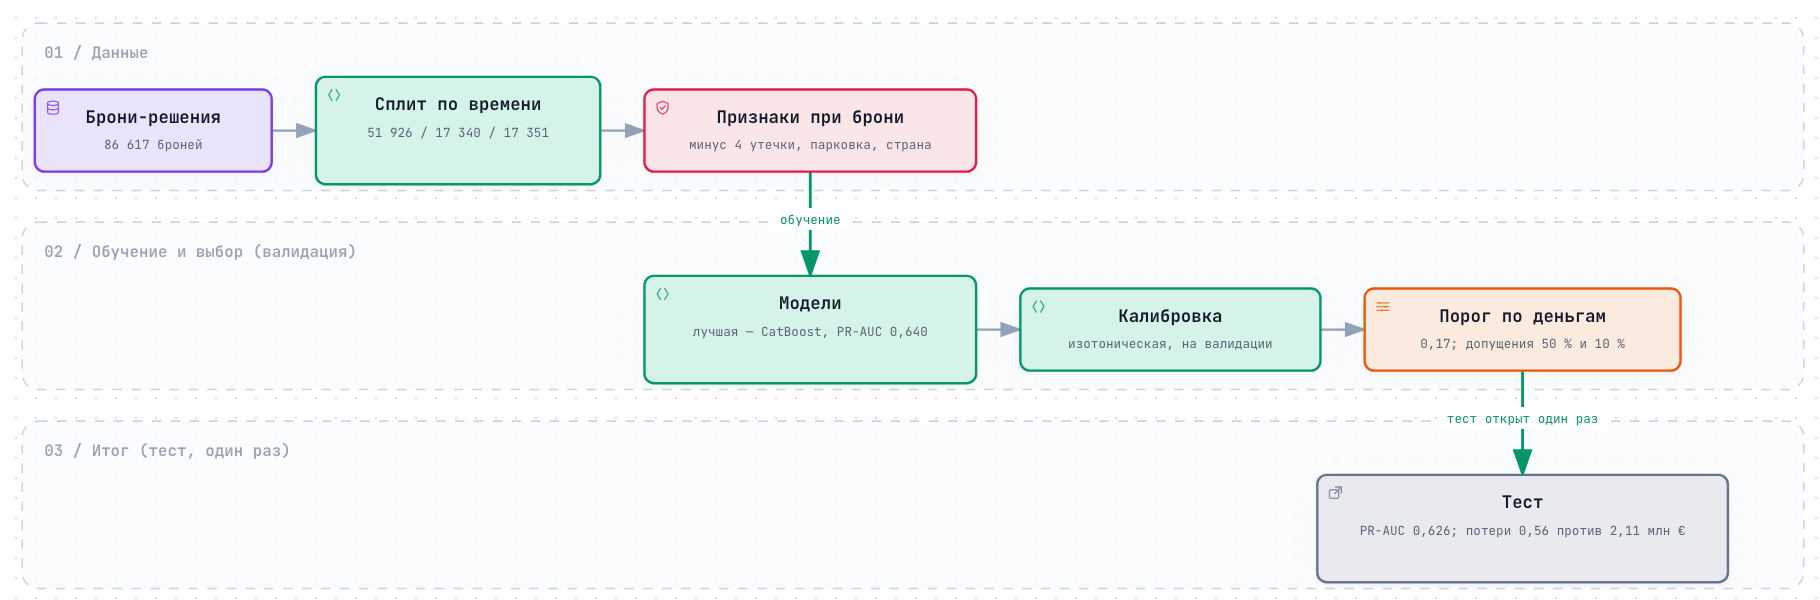

In [28]:
Image(filename=str(FIGURES_DIR / '13_ml_pipeline.png'))

Схема 4 показывает весь конвейер: 86 617 броней делим по времени на обучение (51 926), валидацию (17 340) и тест (17 351), оставляем только признаки, известные при брони (без четырёх утечек, парковки и страны), и сравниваем модели на валидации (CatBoost — PR-AUC 0,640). Калибровку и порог 0,17 выбираем тоже на валидации, а тест открываем один раз в самом конце: PR-AUC 0,626 и потери 0,56 млн € против 2,11 млн € без предоплаты и 0,64 млн € при предоплате со всех. Модель учится на прошлом и проверяется на будущем, поэтому ничего из того, что становится известно только после брони, в неё не попадает.

**Вывод.**

1. **Модель честная.** В неё идут только признаки, известные в момент бронирования: исключены четыре явные утечки и две подозрительные колонки — парковка (ноль отмен у 7 289 броней) и страна (Португалия — 40,7 % отменённых против 27,3 % заехавших). С ними PR-AUC на валидации был бы 0,674 вместо 0,634, а с итогом брони — ровно 1,0; такая «точность» в реальной работе недостижима.
2. **Качество.** На тесте (последние 20 % дат заезда, открыт один раз) настроенный CatBoost даёт PR-AUC 0,626 и ROC-AUC 0,755 при случайном уровне PR-AUC 0,348. Это лучше лучшего простого правила «срок + сегмент» на 0,155 PR-AUC (0,471) и на 0,083 ROC-AUC (0,672). Случайное деление в тех же долях даёт PR-AUC 0,683 и ROC-AUC 0,824; вероятная причина разрыва — перемешанные по датам части, но эксперимент её не доказывает, а честной проверкой считаем деление по времени — так модель будет работать в реальности. Доли 60/20/20 зафиксированы до результатов; при них тест охватывает четыре месяца (май–август), а не только пик сезона, как при 75/15/10.
3. **Почему CatBoost.** Все три модели близки: на тесте логистическая регрессия — 0,620, HistGradientBoosting — 0,611. CatBoost выбран не за сотые доли, а за работу с категориями без one-hot и объяснимость через SHAP. Близость логистической регрессии говорит о том, что отмены хорошо описываются простыми связями.
4. **На что опирается модель.** Срок брони, спецзапросы и сегмент продаж (SHAP 0,51, 0,50 и 0,45), а для отдельных броней — депозит «без возврата» (+3,29 по SHAP у самой рискованной брони; в логистической регрессии шансы отмены примерно в 21 раз выше, чем «без депозита»). Это согласуется с гипотезами H1–H4 шага 2. Всё это **связь, а не причина**: модель описывает, какие брони чаще отменяют, но не объясняет, почему.
5. **Вероятности откалиброваны.** Сырой CatBoost занижает риск (средний прогноз 0,258 при доле отмен 0,293), вероятно, потому что обучен на периоде с меньшей долей отмен (24,7 %). После изотонической калибровки прогнозы на тесте отличаются от реальной доли отмен на несколько процентных пунктов.
6. **Порог по деньгам — 0,17.** Он близок к теоретическому 0,1 / 0,6 ≈ 0,17 и задаётся соотношением цен двух ошибок. На тесте он снижает потери с 2,11 до 0,56 млн €, но предоплату просят у 70,4 % броней. Честное сравнение — с правилом «предоплата со всех» (0,64 млн €): модель экономит относительно него ≈ 0,08 млн € (около 13 %), то есть большая часть экономии при допущениях 50 % / 10 % — от предоплаты как таковой. Порог сильно зависит от допущений о деньгах: на тепловой карте — от 0,06 до 0,42.
7. **Ограничения.** Доля отмен растёт во времени (24,7 % → 29,3 % → 34,8 %), поэтому модель придётся периодически переобучать и перекалибровывать. Цены ошибок (50 % и 10 %) — допущения, в данных их нет. Число спецзапросов оставлено в модели, хотя даты запроса в данных нет: если часть запросов добавляют уже после бронирования, сила этого признака (второй по SHAP) завышена. Данные — два португальских отеля в 2015–2017 годах; перенос на другие отели требует проверки.
8. **Что передаём в шаг 4.** Модель `models/catboost.cbm`, порог 0,17 и функцию `value_at_risk` (стоимость, которую отель теряет при отмене; у броней «без возврата» — 0). Калибратор отдельно не сохраняем: он однозначно восстанавливается из модели — `load_catboost()` → прогноз на той же валидации (`time_split` и `model_frame`) → `fit_calibrator`. На шаге 4 из них собираются правила предоплаты и считается их экономика.